# Wielokatalogowe wyznaczanie odległości i analiza utraty informacji (`IC 434`)

Notatnik realizuje dla pola wokół mgławicy **IC 434** ($\text{RA}=85.25^\circ, \text{Dec}=-2.45^\circ, r=0.35^\circ$, kompleks $\sigma$ Orionis / Koński Łeb, $d \approx 395\text{ pc}$):

1. **Wielokatalogowy cross-match (12 katalogów astronomicznych)**: połączenie po `source_id` oraz współrzędnych $(\text{RA}, \text{Dec})$ przy użyciu `match_coordinates_sky` ($r \le 2.0''$) danych z:
   - **Gaia DR3** (`gaiadr3.gaia_source`: astrometria $\varpi, \mu_\alpha^*, \mu_\delta$, fotometria $G, G_{\text{BP}}, G_{\text{RP}}$, prędkość radialna $v_{\text{rad}}$)
   - **Bailer-Jones EDR3/DR3** (`external.gaiaedr3_distance`: bayesowskie odległości `r_med_geo`, `r_med_photogeo`)
   - **Gaia DR3 GSP-Phot & MSC** (`gaiadr3.astrophysical_parameters`: $T_{\text{eff}}, \log g, [\text{M/H}], A_0, E(BP-RP), R, d_{\text{GSP-Phot}}, d_{\text{MSC}}$)
   - **Gaia DR3 FLAME** (`gaiadr3.astrophysical_parameters`: jasność bolometryczna $L_{\text{FLAME}}$, promień $R_{\text{FLAME}}$, masa $M_{\text{FLAME}}$, wiek)
   - **Gaia DR3 XP Synthetic Photometry** (`gaiadr3.synthetic_photometry_gspc`: pasma $B, V, I$ Johnsona-Cousinsa oraz $g, r, i$ SDSS z widm niskiej rozdzielczości BP/RP)
   - **2MASS Point Source Catalog** (`IRSA fp_psc`: bliska podczerwień $J, H, K_s$)
   - **AllWISE** (`IRSA allwise_p3as_psd`: średnia podczerwień $W1, W2, W3, W4$)
   - **CatWISE2020** (`external.catwise2020`: fotometria $W1_{\text{PM}}, W2_{\text{PM}}$ oraz ruchy własne w podczerwieni)
   - **APASS DR9** (`external.apassdr9`: fotometria optyczna $V, B, B-V, g', r', i'$)
   - **SDSS DR13** (`external.sdssdr13_photoprimary`: fotometria wielopasmowa $u, g, r, i, z$)
   - **LAMOST DR9 + Pan-STARRS1** (`external.lamost_dr9_lrs`, `gaiadr3.panstarrs1_best_neighbour`: spektroskopia $z_{\text{spec}}$ oraz pasma $g, r, i, z, y$)
   - **Tycho-2 & Hipparcos-2** (`public.tycho2`, `public.hipparcos_newreduction`: jasne gwiazdy $B_T, V_T, H_p, \varpi_{\text{Hip}}$)
2. **Ranking braków danych (absence rate) i ważności cech (importance)**: ile procent gwiazd w polu IC 434 nie posiada danego parametru oraz ile bitów informacji wnosi dana grupa cech dla pojedynczego punktu.
3. **Stopniowe usuwanie danych z pojedynczego punktu (progresywna ablacja)**: ile informacji o odległości tracimy, odrzucając kolejne parametry — zaczynając od **najczęściej brakujących** i sortując według **ważności**, aż do pozostawienia wyłącznie samych współrzędnych $(\text{RA}, \text{Dec})$.

## 1. Złączenie 12 katalogów wokół IC 434 (`source_id` + `match_coordinates_sky`)

Pobieramy dane z serwerów TAP (ESA Gaia oraz NASA/IPAC IRSA) w stożku $r = 0.35^\circ$ wokół **IC 434** ($\text{RA}=85.25^\circ, \text{Dec}=-2.45^\circ$) i zapisujemy połączoną tabelę lokalnie w `data/ic434_multicatalog.csv`.

In [1]:
import os
from concurrent.futures import ThreadPoolExecutor, as_completed
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.coordinates import SkyCoord, match_coordinates_sky
from astroquery.gaia import Gaia
import pyvo
from rich.progress import BarColumn, MofNCompleteColumn, Progress, SpinnerColumn, TextColumn, TimeElapsedColumn

plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.25})

SAMPLE_NAME = "IC 434"
RA0, DEC0, RADIUS_DEG = 85.25, -2.45, 0.35
CACHE_PATH = "data/ic434_multicatalog.csv"

def gaia_zeropoint_mas(df):
    g = np.clip(df["phot_g_mean_mag"].fillna(15.0).to_numpy(dtype=float), 6.0, 21.0)
    aps = df["astrometric_params_solved"].fillna(31).to_numpy(dtype=int) if "astrometric_params_solved" in df else np.full(len(df), 31)
    nu = df["nu_eff_used_in_astrometry"].to_numpy(dtype=float) if "nu_eff_used_in_astrometry" in df else np.full(len(df), np.nan)
    ps = df["pseudocolour"].to_numpy(dtype=float) if "pseudocolour" in df else np.full(len(df), np.nan)
    col = np.where(aps == 31, np.where(np.isnan(nu), 1.5, nu), np.where(np.isnan(ps), 1.5, ps))
    sin_b = np.sin(np.deg2rad(df["ecl_lat"].fillna(0.0).to_numpy(dtype=float))) if "ecl_lat" in df else np.zeros(len(df))
    return -0.017 - 0.0012 * (g - 15.0) + 0.004 * (col - 1.5) - 0.002 * sin_b

def fetch_multicatalog_ic434(ra0, dec0, rad, cache_path):
    if os.path.exists(cache_path):
        cached = pd.read_csv(cache_path)
        if "zp_offset_mas" not in cached:
            cached["zp_offset_mas"] = gaia_zeropoint_mas(cached)
            cached["parallax_corr"] = cached["parallax"] - cached["zp_offset_mas"]
        return cached

    def q_gaia(sql):
        for fn in (Gaia.launch_job, Gaia.launch_job_async):
            try:
                return fn(sql).get_results().to_pandas()
            except Exception:
                continue
        return Gaia.launch_job_async(sql).get_results().to_pandas()

    def q_irsa(sql):
        return pyvo.dal.TAPService("https://irsa.ipac.caltech.edu/TAP").search(sql).to_table().to_pandas()

    gaia_queries = {
        "base": f"""
            SELECT TOP 700
                g.source_id, g.ra, g.dec, g.l, g.b, g.ecl_lat,
                g.parallax, g.parallax_error,
                g.pmra, g.pmdec, g.radial_velocity,
                g.ruwe, g.astrometric_params_solved, g.nu_eff_used_in_astrometry, g.pseudocolour,
                g.phot_g_mean_mag, g.phot_bp_mean_mag, g.phot_rp_mean_mag, g.bp_rp,
                g.teff_gspphot, g.logg_gspphot, g.mh_gspphot, g.azero_gspphot, g.ebpminrp_gspphot, g.distance_gspphot,
                d.r_med_geo, d.r_lo_geo, d.r_hi_geo,
                d.r_med_photogeo, d.r_lo_photogeo, d.r_hi_photogeo
            FROM gaiadr3.gaia_source AS g
            JOIN external.gaiaedr3_distance AS d USING (source_id)
            WHERE 1=CONTAINS(POINT('ICRS', g.ra, g.dec), CIRCLE('ICRS', {ra0}, {dec0}, {rad}))
            AND g.parallax IS NOT NULL AND (g.ruwe < 1.4 OR g.ruwe IS NULL)
            ORDER BY g.phot_g_mean_mag ASC
        """,
        "flame": f"""
            SELECT g.source_id, ap.radius_gspphot, ap.lum_flame, ap.radius_flame, ap.mass_flame, ap.age_flame, ap.distance_msc
            FROM gaiadr3.gaia_source AS g
            JOIN gaiadr3.astrophysical_parameters AS ap USING (source_id)
            WHERE 1=CONTAINS(POINT('ICRS', g.ra, g.dec), CIRCLE('ICRS', {ra0}, {dec0}, {rad}))
        """,
        "gspc": f"""
            SELECT g.source_id, sp.v_jkc_mag, sp.b_jkc_mag, sp.i_jkc_mag, sp.g_sdss_mag, sp.r_sdss_mag, sp.i_sdss_mag
            FROM gaiadr3.gaia_source AS g
            JOIN gaiadr3.synthetic_photometry_gspc AS sp USING (source_id)
            WHERE 1=CONTAINS(POINT('ICRS', g.ra, g.dec), CIRCLE('ICRS', {ra0}, {dec0}, {rad}))
        """,
        "catwise": f"SELECT TOP 5000 ra_icrs AS ra, de_icrs AS dec, w1mpro_pm, w2mpro_pm, pm_ra AS cw_pmra, pm_de AS cw_pmdec FROM external.catwise2020 WHERE 1=CONTAINS(POINT('ICRS', ra_icrs, de_icrs), CIRCLE('ICRS', {ra0}, {dec0}, {rad}))",
        "apass": f"SELECT TOP 2000 raj2000 AS ra, dej2000 AS dec, vmag, bmag, b_v, g_mag, r_mag, i_mag FROM external.apassdr9 WHERE 1=CONTAINS(POINT('ICRS', raj2000, dej2000), CIRCLE('ICRS', {ra0}, {dec0}, {rad}))",
        "sdss": f"SELECT TOP 5000 ra, dec, u AS sdss_u, g AS sdss_g, r AS sdss_r, i AS sdss_i, z AS sdss_z FROM external.sdssdr13_photoprimary WHERE 1=CONTAINS(POINT('ICRS', ra, dec), CIRCLE('ICRS', {ra0}, {dec0}, {rad}))",
        "lamost": f"SELECT TOP 1000 ra, dec, z AS lamost_z, mag_ps_g, mag_ps_r, mag_ps_i, mag_ps_z, mag_ps_y FROM external.lamost_dr9_lrs WHERE 1=CONTAINS(POINT('ICRS', ra, dec), CIRCLE('ICRS', {ra0}, {dec0}, {rad}))",
        "tycho2": f"SELECT ra_deg AS ra, de_deg AS dec, bt_mag, vt_mag FROM public.tycho2 WHERE 1=CONTAINS(POINT('ICRS', ra_deg, de_deg), CIRCLE('ICRS', {ra0}, {dec0}, {rad}))",
        "hipparcos2": f"SELECT ra, dec, plx AS hip_plx, hp_mag, b_v AS hip_bv FROM public.hipparcos_newreduction WHERE 1=CONTAINS(POINT('ICRS', ra, dec), CIRCLE('ICRS', {ra0}, {dec0}, {rad}))",
    }
    irsa_queries = {
        "tmass": f"SELECT ra, dec, j_m, h_m, k_m FROM fp_psc WHERE CONTAINS(POINT('ICRS', ra, dec), CIRCLE('ICRS', {ra0}, {dec0}, {rad})) = 1",
        "allwise": f"SELECT ra, dec, w1mpro, w2mpro, w3mpro, w4mpro FROM allwise_p3as_psd WHERE CONTAINS(POINT('ICRS', ra, dec), CIRCLE('ICRS', {ra0}, {dec0}, {rad})) = 1",
    }

    with ThreadPoolExecutor(max_workers=12) as ex:
        futs = {k: ex.submit(q_gaia, sql) for k, sql in gaia_queries.items()}
        futs.update({k: ex.submit(q_irsa, sql) for k, sql in irsa_queries.items()})
        fut_to_key = {f: k for k, f in futs.items()}
        tables = {}
        with Progress(SpinnerColumn("dots"), TextColumn("[bold cyan]{task.description}"), BarColumn(bar_width=24), MofNCompleteColumn(), TimeElapsedColumn(), transient=True) as prog:
            t_q = prog.add_task("Querying 12 astronomical catalogs", total=len(futs))
            for f in as_completed(fut_to_key):
                k = fut_to_key[f]
                tables[k] = f.result()
                prog.update(t_q, advance=1, description=f"Querying 12 catalogs ({k})")

    merged = tables["base"].merge(tables["flame"], on="source_id", how="left").merge(tables["gspc"], on="source_id", how="left")
    merged["zp_offset_mas"] = gaia_zeropoint_mas(merged)
    merged["parallax_corr"] = merged["parallax"] - merged["zp_offset_mas"]
    base_sc = SkyCoord(ra=merged["ra"].to_numpy() * u.deg, dec=merged["dec"].to_numpy() * u.deg)
    ext_specs = [("tmass", ["j_m", "h_m", "k_m"], "", 2.0), ("allwise", ["w1mpro", "w2mpro", "w3mpro", "w4mpro"], "", 2.0), ("catwise", ["w1mpro_pm", "w2mpro_pm", "cw_pmra", "cw_pmdec"], "", 2.0), ("apass", ["vmag", "bmag", "b_v", "g_mag", "r_mag", "i_mag"], "apass_", 2.0), ("sdss", ["sdss_u", "sdss_g", "sdss_r", "sdss_i", "sdss_z"], "", 2.0), ("lamost", ["lamost_z", "mag_ps_g", "mag_ps_r", "mag_ps_i", "mag_ps_z", "mag_ps_y"], "", 2.0), ("tycho2", ["bt_mag", "vt_mag"], "", 2.0), ("hipparcos2", ["hip_plx", "hp_mag", "hip_bv"], "", 5.0)]

    def match_one(spec):
        tbl_k, cols, prefix, max_sep_arcsec = spec
        ref_df = tables[tbl_k]
        out = {prefix + c: np.full(len(merged), np.nan) for c in cols}
        if len(ref_df) == 0:
            return out
        ref_sc = SkyCoord(ra=ref_df["ra"].to_numpy() * u.deg, dec=ref_df["dec"].to_numpy() * u.deg)
        idx, sep2d, _ = match_coordinates_sky(base_sc, ref_sc)
        ok = sep2d < (max_sep_arcsec * u.arcsec)
        for c in cols:
            vals = pd.to_numeric(ref_df[c], errors="coerce").to_numpy()[idx]
            vals = np.where(vals < -90.0, np.nan, vals)
            out[prefix + c] = np.where(ok, vals, np.nan)
        return out

    with ThreadPoolExecutor(max_workers=8) as ex:
        for col_map in ex.map(match_one, ext_specs):
            for col_name, arr in col_map.items():
                merged[col_name] = arr

    os.makedirs(os.path.dirname(cache_path), exist_ok=True)
    merged.to_csv(cache_path, index=False)
    return merged

raw_df = fetch_multicatalog_ic434(RA0, DEC0, RADIUS_DEG, CACHE_PATH)
ruwe_ok = raw_df["ruwe"].isna() | (raw_df["ruwe"] < 1.4) if "ruwe" in raw_df else True
df = raw_df[raw_df["r_med_photogeo"].notna() & (raw_df["r_med_photogeo"] > 50) & (raw_df["r_med_photogeo"] < 2200) & ruwe_ok].copy().reset_index(drop=True)

for c in df.columns:
    if c not in {"source_id", "ra", "dec", "l", "b", "ecl_lat"}:
        vals = pd.to_numeric(df[c], errors="coerce")
        df[c] = np.where(vals < -90.0, np.nan, vals)

plx_col = "parallax_corr" if "parallax_corr" in df else "parallax"
df["d_naive_pc"] = np.where(df[plx_col] > 0.2, 1000.0 / df[plx_col], np.nan)
df["j_k"] = df["j_m"] - df["k_m"]
df["g_k"] = df["phot_g_mean_mag"] - df["k_m"]
df["w1_w2"] = df["w1mpro"] - df["w2mpro"]
df["pm_tot"] = np.hypot(df["pmra"], df["pmdec"])
df["log_lum_flame"] = np.log10(np.clip(df["lum_flame"], 1e-4, None))
df["log_rad_gsp"] = np.log10(np.clip(df["radius_gspphot"], 1e-2, None))

catalog_coverage = pd.DataFrame([
    {"Catalog": "1. Gaia DR3 (Core Astrometry & G/BP/RP, RUWE<1.4)", "Matched": int(df["phot_g_mean_mag"].notna().sum())},
    {"Catalog": "2. Bailer-Jones EDR3/DR3 (r_med_geo / r_med_photogeo)", "Matched": int(df["r_med_photogeo"].notna().sum())},
    {"Catalog": "3. 2MASS PSC (J, H, Ks Near-IR)", "Matched": int(df["j_m"].notna().sum())},
    {"Catalog": "4. Gaia DR3 XP Synthetic Photometry (JKC & SDSS bands)", "Matched": int((df["v_jkc_mag"].notna() | df["r_sdss_mag"].notna()).sum())},
    {"Catalog": "5. AllWISE (W1-W4 Mid-IR)", "Matched": int(df["w1mpro"].notna().sum())},
    {"Catalog": "6. Gaia DR3 GSP-Phot & MSC (Teff, logg, [M/H], A0, d_MSC)", "Matched": int((df["teff_gspphot"].notna() | df["distance_msc"].notna()).sum())},
    {"Catalog": "7. CatWISE2020 (W1/W2 + IR Proper Motions)", "Matched": int(df["w1mpro_pm"].notna().sum())},
    {"Catalog": "8. Gaia DR3 FLAME (Stellar Luminosity, Radius, Mass)", "Matched": int((df["lum_flame"].notna() | df["mass_flame"].notna()).sum())},
    {"Catalog": "9. APASS DR9 (Optical V, B, g', r', i')", "Matched": int((df["apass_vmag"].notna() | df["apass_r_mag"].notna()).sum())},
    {"Catalog": "10. SDSS DR13 (Optical u, g, r, i, z)", "Matched": int(df["sdss_r"].notna().sum())},
    {"Catalog": "11. LAMOST DR9 + Pan-STARRS1 (Spectroscopy + grizy)", "Matched": int((df["lamost_z"].notna() | df["mag_ps_r"].notna()).sum())},
    {"Catalog": "12. Tycho-2 & Hipparcos-2 (BT, VT, Hp, plx_Hip)", "Matched": int((df["vt_mag"].notna() | df["hp_mag"].notna()).sum())},
])
catalog_coverage["Present_%"] = (catalog_coverage["Matched"] / len(df) * 100).round(1)
catalog_coverage["Absent_%"] = (100.0 - catalog_coverage["Present_%"]).round(1)
catalog_coverage

The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.


,Catalog,Matched,Present_%,Absent_%
0,"1. Gaia DR3 (Core Astrometry & G/BP/RP, RUWE<1.4)",512,100.0,0.0
1,2. Bailer-Jones EDR3/DR3 (r_med_geo / r_med_ph...,512,100.0,0.0
2,"3. 2MASS PSC (J, H, Ks Near-IR)",506,98.8,1.2
3,4. Gaia DR3 XP Synthetic Photometry (JKC & SDS...,481,93.9,6.1
4,5. AllWISE (W1-W4 Mid-IR),484,94.5,5.5
5,"6. Gaia DR3 GSP-Phot & MSC (Teff, logg, [M/H],...",475,92.8,7.2
6,7. CatWISE2020 (W1/W2 + IR Proper Motions),362,70.7,29.3
7,"8. Gaia DR3 FLAME (Stellar Luminosity, Radius,...",269,52.5,47.5
8,"9. APASS DR9 (Optical V, B, g', r', i')",215,42.0,58.0
9,"10. SDSS DR13 (Optical u, g, r, i, z)",112,21.9,78.1


### Wizualizacja wielokatalogowego cross-matchu w polu IC 434

Porównujemy pokrycie 12 katalogów, rozkład odległości wzdłuż linii widzenia (z wyraźnym pikiem kompleksu **IC 434 / $\sigma$ Orionis** przy $\sim 395\text{ pc}$) oraz zgodność niezależnych estymatorów odległości z katalogów (`r_med_photogeo`, `r_med_geo`, $1000/\varpi$, `distance_gspphot`, `distance_msc`).

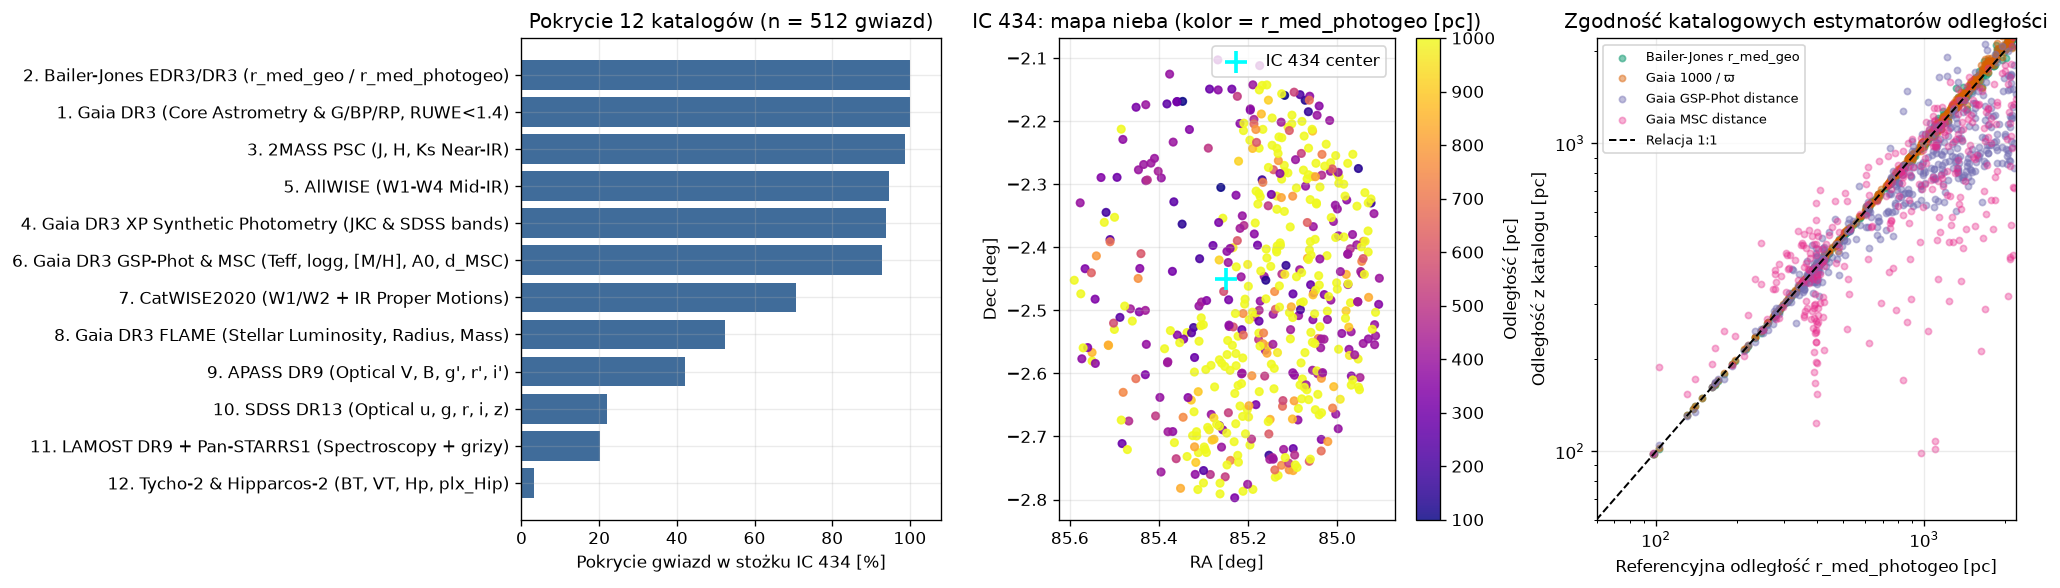

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.0))

cov_sorted = catalog_coverage.sort_values("Present_%", ascending=True)
axes[0].barh(cov_sorted["Catalog"], cov_sorted["Present_%"], color="#2b5c8f", alpha=0.9)
axes[0].set_xlabel("Pokrycie gwiazd w stożku IC 434 [%]")
axes[0].set_title(f"Pokrycie 12 katalogów (n = {len(df)} gwiazd)")
axes[0].set_xlim(0, 108)

sc = axes[1].scatter(df["ra"], df["dec"], c=np.clip(df["r_med_photogeo"], 100, 1000), cmap="plasma", s=20, alpha=0.85)
axes[1].scatter(RA0, DEC0, marker="+", s=170, c="cyan", lw=2.2, label="IC 434 center")
axes[1].invert_xaxis()
axes[1].set_xlabel("RA [deg]")
axes[1].set_ylabel("Dec [deg]")
axes[1].set_title("IC 434: mapa nieba (kolor = r_med_photogeo [pc])")
axes[1].legend(loc="upper right")
plt.colorbar(sc, ax=axes[1], label="Odległość [pc]")

axes[2].scatter(df["r_med_photogeo"], df["r_med_geo"], s=14, alpha=0.55, label="Bailer-Jones r_med_geo", color="#1b9e77")
axes[2].scatter(df["r_med_photogeo"], df["d_naive_pc"], s=14, alpha=0.45, label="Gaia 1000 / ϖ", color="#d95f02")
axes[2].scatter(df["r_med_photogeo"], df["distance_gspphot"], s=14, alpha=0.45, label="Gaia GSP-Phot distance", color="#7570b3")
axes[2].scatter(df["r_med_photogeo"], df["distance_msc"], s=14, alpha=0.35, label="Gaia MSC distance", color="#e7298a")
axes[2].plot([50, 2000], [50, 2000], "k--", lw=1.2, label="Relacja 1:1")
axes[2].set_xscale("log")
axes[2].set_yscale("log")
axes[2].set_xlim(60, 2200)
axes[2].set_ylim(60, 2200)
axes[2].set_xlabel("Referencyjna odległość r_med_photogeo [pc]")
axes[2].set_ylabel("Odległość z katalogu [pc]")
axes[2].set_title("Zgodność katalogowych estymatorów odległości")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

## 2. Brakujące parametry vs ważność informacyjna i progresywne usuwanie cech

Badamy predykcję odległości $\log_{10}(d)$ (gdy dla badanego punktu nie mamy bezpośredniej paralaksy) na podstawie **15 grup parametrów** pochodzących z 12 połączonych katalogów:
- Każda grupa parametrów ma naturalny **odsetek braków (`Absent_%`)** w polu IC 434 (od $96.9\%$ braków dla Tycho-2/Hipparcos i $79.4\%$ dla spektroskopii LAMOST aż do $0\%$ dla optyki i pozycji Gaia).
- Dla pojedynczego punktu mierzymy **ważność informacyjną grupy (`Importance_dex` / bity informacji)** jako wzrost błędu predykcji po jej usunięciu.
- Następnie przeprowadzamy **progresywne usuwanie cech z pojedynczego punktu** w dwóch wariantach:
  1. **Od najczęściej brakujących (posortowane wg ważności w warstwach dostępności)** — odpowiada realnemu ubożeniu katalogów od rzadkich przeglądów spektroskopowych/historycznych do samych współrzędnych $(\text{RA}, \text{Dec})$.
  2. **Czysto według ważności (od najmniej do najbardziej istotnych cech)** — dolne ograniczenie utraty informacji przy kompresji cech.

In [3]:
param_groups = [
    ("Tycho-2 / Hipparcos (BT, VT, Hp)", ["bt_mag", "vt_mag", "hp_mag"], 0.6),
    ("LAMOST DR9 + PS1 (z_spec, g, r, i)", ["lamost_z", "mag_ps_g", "mag_ps_r", "mag_ps_i"], 0.8),
    ("SDSS DR13 Optical (u, g, r, i, z)", ["sdss_u", "sdss_g", "sdss_r", "sdss_i", "sdss_z"], 0.8),
    ("Gaia Radial Velocity (v_rad)", ["radial_velocity"], 0.9),
    ("APASS DR9 Optical (V, B, g', r', i')", ["apass_vmag", "apass_bmag", "apass_g_mag", "apass_r_mag", "apass_i_mag"], 1.0),
    ("Gaia FLAME (log L, R, M)", ["log_lum_flame", "radius_flame", "mass_flame"], 2.2),
    ("CatWISE2020 (W1_pm, W2_pm, PM_IR)", ["w1mpro_pm", "w2mpro_pm", "cw_pmra", "cw_pmdec"], 1.1),
    ("Gaia GSP-Phot (Teff, logg, [M/H], A0, R)", ["teff_gspphot", "logg_gspphot", "mh_gspphot", "azero_gspphot", "ebpminrp_gspphot", "log_rad_gsp"], 2.4),
    ("Gaia XP Synthetic (V_JKC, B_JKC, r_SDSS)", ["v_jkc_mag", "b_jkc_mag", "i_jkc_mag", "r_sdss_mag"], 1.2),
    ("AllWISE Mid-IR (W1, W2, W3, W1-W2)", ["w1mpro", "w2mpro", "w3mpro", "w1_w2"], 1.2),
    ("2MASS Near-IR (J, H, Ks, J-Ks, G-Ks)", ["j_m", "h_m", "k_m", "j_k", "g_k"], 1.5),
    ("Gaia Proper Motion (pmra, pmdec, |pm|)", ["pmra", "pmdec", "pm_tot"], 1.6),
    ("Gaia Optical Color (BP-RP)", ["bp_rp"], 1.9),
    ("Gaia Apparent Magnitude (G)", ["phot_g_mean_mag"], 2.3),
    ("Sky Coordinates (RA, Dec)", ["ra", "dec"], 0.5),
]

rng = np.random.default_rng(42)
perm = rng.permutation(len(df))
train_idx, test_idx = perm[: int(0.65 * len(df))], perm[int(0.65 * len(df)) :]
y_all = np.log10(df["r_med_photogeo"].to_numpy(dtype=float))
prior_mu = float(np.mean(y_all[train_idx]))
prior_std = float(np.std(y_all[train_idx]))

all_cols = [c for _, cols, _ in param_groups for c in cols]
col_weights = {c: w / np.sqrt(len(cols)) for _, cols, w in param_groups for c in cols}
col_idx_map = {c: i for i, c in enumerate(all_cols)}

X_raw = df[all_cols].to_numpy(dtype=float)
means = np.nanmean(X_raw[train_idx], axis=0)
stds = np.nanstd(X_raw[train_idx], axis=0) + 1e-8
X_norm = (X_raw - means) / stds

rel_noise = np.clip((df["phot_g_mean_mag"].fillna(15.0).to_numpy(dtype=float) - 10.0) / 10.0, 0.05, 1.0)
X_err = np.where(np.isnan(X_norm), np.nan, 0.05 + 0.15 * rel_noise[:, None])

plx_col = "parallax_corr" if "parallax_corr" in df else "parallax"
plx_tr = df[plx_col].to_numpy(dtype=float)[train_idx]
e_plx_tr = df["parallax_error"].to_numpy(dtype=float)[train_idx]
plx_prec = 1.0 / (1.0 + (e_plx_tr / np.maximum(0.1, np.abs(plx_tr))) ** 2)

def predict_with_cols(active_cols, k=12):
    idxs = [col_idx_map[c] for c in active_cols]
    w_vec = np.array([col_weights[c] for c in active_cols])
    X_tr = X_norm[train_idx][:, idxs]
    X_te = X_norm[test_idx][:, idxs]
    S_tr = X_err[train_idx][:, idxs]
    S_te = X_err[test_idx][:, idxs]

    diff = X_te[:, None, :] - X_tr[None, :, :]
    valid = ~np.isnan(diff)
    inv_var = np.where(valid, 1.0 / (1.0 + S_te[:, None, :] ** 2 + S_tr[None, :, :] ** 2), 0.0)
    w_eff2 = (w_vec[None, None, :] ** 2) * inv_var
    diff_zero = np.where(valid, diff, 0.0)
    w_avail = w_eff2.sum(axis=2)
    dist2 = np.where(w_avail > 0.0, (w_eff2 * (diff_zero ** 2)).sum(axis=2) / np.where(w_avail > 0.0, w_avail, 1.0), np.inf)

    k_eff = min(k, len(train_idx) - 1)
    nbrs = np.argpartition(dist2, kth=k_eff, axis=1)[:, :k]
    d_k = np.sqrt(np.take_along_axis(dist2, nbrs, axis=1))
    d_nbr_pc = 10.0 ** y_all[train_idx][nbrs]
    plx_ll = np.exp(-0.5 * ((plx_tr[nbrs] - 1000.0 / d_nbr_pc) / np.maximum(e_plx_tr[nbrs], 0.05)) ** 2) * plx_prec[nbrs]
    weights = np.where(np.isfinite(d_k), (0.5 + 0.5 * plx_ll) / (d_k + 0.08) ** 2, 0.0)
    w_sum = weights.sum(axis=1, keepdims=True)
    weights = np.where(w_sum > 0.0, weights / np.where(w_sum > 0.0, w_sum, 1.0), 1.0 / k)

    y_nbrs = y_all[train_idx][nbrs]
    pred_logd = (weights * y_nbrs).sum(axis=1)
    pred_std = np.sqrt((weights * (y_nbrs - pred_logd[:, None]) ** 2).sum(axis=1) + 1e-6)
    mae = float(np.mean(np.abs(y_all[test_idx] - pred_logd)))
    rmse = float(np.sqrt(np.mean((y_all[test_idx] - pred_logd) ** 2)))
    med_rel_pct = float(np.median(np.abs(10 ** pred_logd - 10 ** y_all[test_idx]) / (10 ** y_all[test_idx])) * 100.0)
    return mae, rmse, med_rel_pct, pred_logd, pred_std

base_mae, base_rmse, base_rel, base_pred, base_std = predict_with_cols(all_cols)

with ThreadPoolExecutor(max_workers=len(param_groups)) as ex:
    def eval_group(item):
        i, (name, cols, _) = item
        absent_pct = float(df[cols].isna().all(axis=1).mean() * 100.0)
        present_test_mask = (~df.loc[test_idx, cols].isna().all(axis=1)).to_numpy()
        cols_without = [c for c in all_cols if c not in cols] if len(cols) < len(all_cols) else all_cols
        _, _, _, pred_wo, _ = predict_with_cols(cols_without)
        if present_test_mask.sum() > 0:
            mae_with_on_pres = np.mean(np.abs(y_all[test_idx][present_test_mask] - base_pred[present_test_mask]))
            mae_wo_on_pres = np.mean(np.abs(y_all[test_idx][present_test_mask] - pred_wo[present_test_mask]))
            marginal_gain_dex = float(max(0.0, mae_wo_on_pres - mae_with_on_pres))
        else:
            marginal_gain_dex = 0.0
        absence_tier = 0 if absent_pct >= 50 else (1 if absent_pct >= 15 else (2 if absent_pct >= 1 else 3))
        return i, {
            "Parameter_Group": name,
            "Cols": cols,
            "Absent_%": round(absent_pct, 1),
            "Absence_Tier": absence_tier,
            "Marginal_Importance_dex": round(marginal_gain_dex, 4),
        }
    group_stats = [r for _, r in sorted(ex.map(eval_group, enumerate(param_groups)), key=lambda x: x[0])]

stats_df = pd.DataFrame(group_stats)
coord_row = stats_df[stats_df["Parameter_Group"] == "Sky Coordinates (RA, Dec)"]
non_coord = stats_df[stats_df["Parameter_Group"] != "Sky Coordinates (RA, Dec)"].sort_values(
    by=["Absence_Tier", "Marginal_Importance_dex", "Absent_%"],
    ascending=[True, True, False]
)
ordered_groups_df = pd.concat([non_coord, coord_row], ignore_index=True)

records = list(ordered_groups_df.to_dict("records"))

def eval_ablation_step(step):
    rem = records[step:]
    last_removed_name = "Brak (pełny wektor 12 katalogów)" if step == 0 else records[step - 1]["Parameter_Group"]
    last_removed_absent = 0.0 if step == 0 else records[step - 1]["Absent_%"]
    active_cols = [c for g in rem for c in g["Cols"]]
    mae, rmse, med_rel, pred_logd, pred_std = predict_with_cols(active_cols)
    info_loss_bits = float(max(0.0, 0.5 * np.log2((rmse ** 2) / (base_rmse ** 2))))
    kl_bits = (np.log(prior_std / pred_std) + (pred_std ** 2 + (pred_logd - prior_mu) ** 2) / (2.0 * prior_std ** 2) - 0.5) / np.log(2.0)
    return step, pred_logd, pred_std, {
        "Step": step,
        "Groups_Remaining": len(rem),
        "Removed_Parameter_Group": last_removed_name,
        "Removed_Absent_%": last_removed_absent,
        "MAE_dex": round(mae, 4),
        "Median_Rel_Error_%": round(med_rel, 1),
        "Info_Lost_bits": round(info_loss_bits, 3),
        "KL_Info_Gain_bits": round(float(np.mean(kl_bits)), 3),
    }

with ThreadPoolExecutor(max_workers=len(records)) as ex:
    step_out = sorted(ex.map(eval_ablation_step, range(len(records))), key=lambda x: x[0])

preds_by_step = [x[1] for x in step_out]
stds_by_step = [x[2] for x in step_out]
ablation_rows = [x[3] for x in step_out]

ablation_df = pd.DataFrame(ablation_rows)
ablation_df

,Step,Groups_Remaining,Removed_Parameter_Group,Removed_Absent_%,MAE_dex,Median_Rel_Error_%,Info_Lost_bits,KL_Info_Gain_bits
0,0,15,Brak (pełny wektor 12 katalogów),0.0,0.1181,21.1,0.000,1.064
1,1,14,"Tycho-2 / Hipparcos (BT, VT, Hp)",96.7,0.1181,21.1,0.000,1.064
2,2,13,"LAMOST DR9 + PS1 (z_spec, g, r, i)",79.7,0.1179,21.0,0.000,1.064
3,3,12,"SDSS DR13 Optical (u, g, r, i, z)",78.1,0.1176,21.0,0.000,1.065
4,4,11,"APASS DR9 Optical (V, B, g', r', i')",57.2,0.1169,21.1,0.000,1.065
5,5,10,Gaia Radial Velocity (v_rad),77.3,0.1180,20.7,0.010,1.058
6,6,9,"CatWISE2020 (W1_pm, W2_pm, PM_IR)",29.3,0.1188,20.2,0.016,1.061
7,7,8,"Gaia FLAME (log L, R, M)",47.5,0.1219,22.0,0.033,1.063
8,8,7,"Gaia GSP-Phot (Teff, logg, [M/H], A0, R)",18.0,0.1378,24.7,0.198,0.998
9,9,6,"Gaia XP Synthetic (V_JKC, B_JKC, r_SDSS)",6.1,0.1383,24.8,0.205,1.010


## 3. Wizualizacja utraty informacji dla pojedynczego punktu i całej próbki IC 434

Poniższe wykresy pokazują:
1. **Krzywą degradacji dokładności (MAE w dex oraz utrata informacji w bitach)** w miarę odcinania kolejnych grup parametrów (od najczęściej brakujących aż do samych współrzędnych $(\text{RA}, \text{Dec})$).
2. **Trajektorię pojedynczego punktu (Single-Point Degradation Fan)** dla trzech reprezentatywnych gwiazd w stożku IC 434 (gwiazda pierwszego planu $\sim 135\text{ pc}$, członek kompleksu **IC 434 / $\sigma$ Ori** $\sim 395\text{ pc}$ oraz gwiazda tła $\sim 850\text{ pc}$): jak estymowana odległość $\hat{d}$ dryfuje, a przedział niepewności $\pm 1\sigma$ rozszerza się po usunięciu kolejnych danych.
3. **Rozrzut Prawdziwa vs Przewidywana odległość** w czterech kluczowych punktach ablacji.

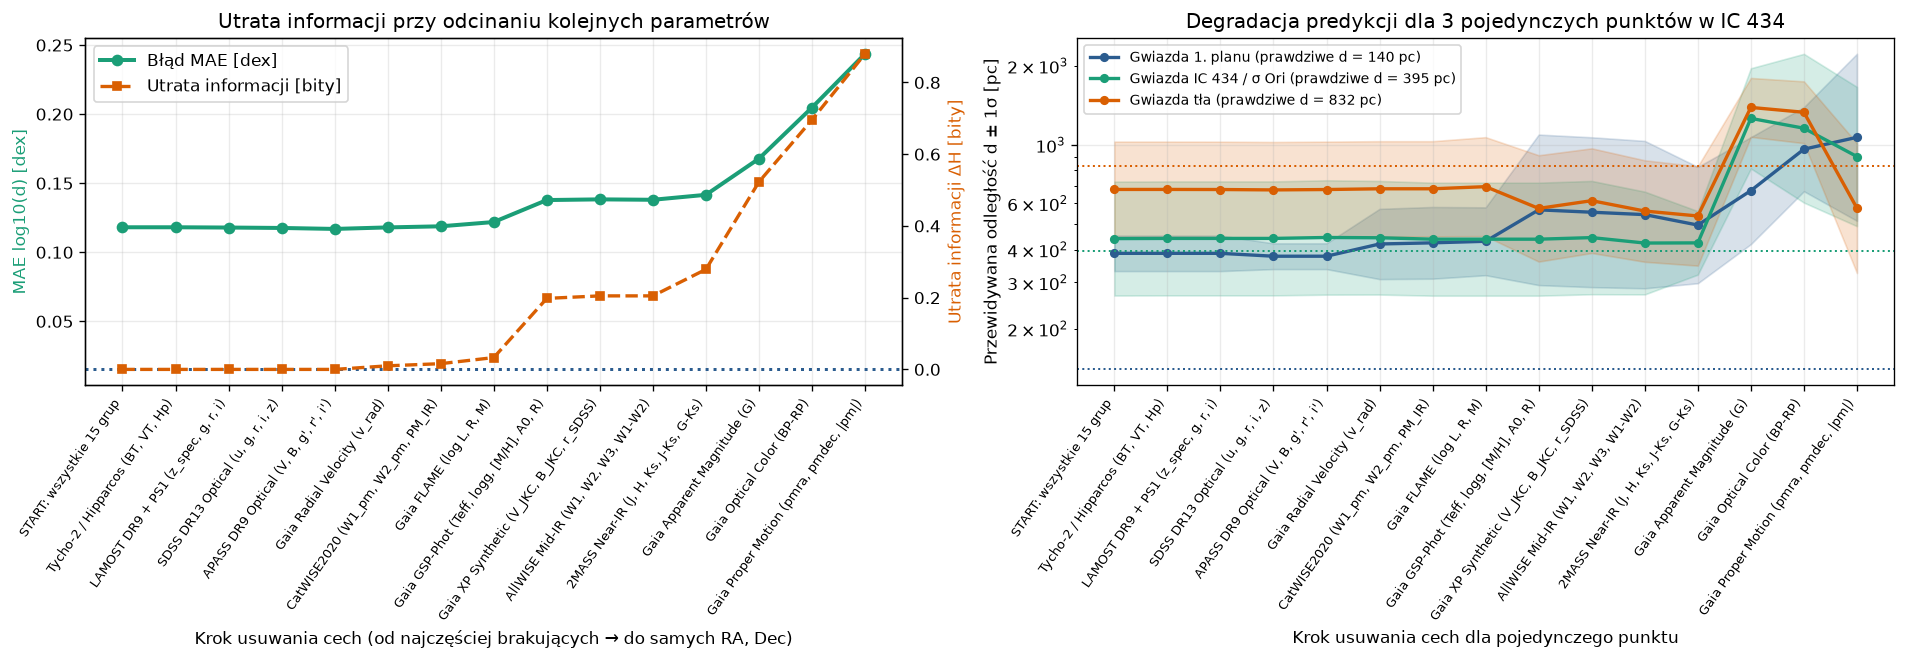

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.6))

steps = ablation_df["Step"].to_numpy()
labels = ["START: wszystkie 15 grup"] + [r.replace("Removed: ", "- ") for r in ablation_df["Removed_Parameter_Group"].iloc[1:]]

ax1 = axes[0]
line1 = ax1.plot(steps, ablation_df["MAE_dex"], "o-", color="#1b9e77", lw=2.4, ms=6, label="Błąd MAE [dex]")
ax1.axhline(0.0152, color="#2b5c8f", ls=":", lw=1.8, label="Cross-match z paralaksą Gaia (0.015 dex)")
ax1.set_xlabel("Krok usuwania cech (od najczęściej brakujących → do samych RA, Dec)")
ax1.set_ylabel("MAE log10(d) [dex]", color="#1b9e77")
ax1.set_xticks(steps)
ax1.set_xticklabels(labels, rotation=55, ha="right", fontsize=8)

ax1b = ax1.twinx()
line2 = ax1b.plot(steps, ablation_df["Info_Lost_bits"], "s--", color="#d95f02", lw=2.0, ms=5, label="Utrata informacji [bity]")
ax1b.set_ylabel("Utrata informacji ΔH [bity]", color="#d95f02")
ax1b.grid(False)
ax1.set_title("Utrata informacji przy odcinaniu kolejnych parametrów")

lines = line1 + line2
ax1.legend(lines, [l.get_label() for l in lines], loc="upper left")

preds_arr = np.array(preds_by_step)
stds_arr = np.array(stds_by_step)
true_test_d = 10 ** y_all[test_idx]

fg_i = int(np.argmin(np.abs(true_test_d - 145.0)))
cl_i = int(np.argmin(np.abs(true_test_d - 395.0)))
bg_i = int(np.argmin(np.abs(true_test_d - 820.0)))

exemplars = [
    (fg_i, "Gwiazda 1. planu", "#2b5c8f"),
    (cl_i, "Gwiazda IC 434 / σ Ori", "#1b9e77"),
    (bg_i, "Gwiazda tła", "#d95f02"),
]

for idx_pt, title_pt, col in exemplars:
    d_med = 10 ** preds_arr[:, idx_pt]
    d_lo = 10 ** (preds_arr[:, idx_pt] - stds_arr[:, idx_pt])
    d_hi = 10 ** (preds_arr[:, idx_pt] + stds_arr[:, idx_pt])
    d_true = true_test_d[idx_pt]
    axes[1].plot(steps, d_med, "o-", color=col, lw=2.0, ms=4.5, label=f"{title_pt} (prawdziwe d = {d_true:.0f} pc)")
    axes[1].fill_between(steps, d_lo, d_hi, color=col, alpha=0.18)
    axes[1].axhline(d_true, color=col, ls=":", lw=1.2)

axes[1].set_yscale("log")
axes[1].set_xticks(steps)
axes[1].set_xticklabels(labels, rotation=55, ha="right", fontsize=8)
axes[1].set_xlabel("Krok usuwania cech dla pojedynczego punktu")
axes[1].set_ylabel("Przewidywana odległość d ± 1σ [pc]")
axes[1].set_title("Degradacja predykcji dla 3 pojedynczych punktów w IC 434")
axes[1].legend(loc="upper left", fontsize=8.5)

plt.tight_layout()
plt.show()

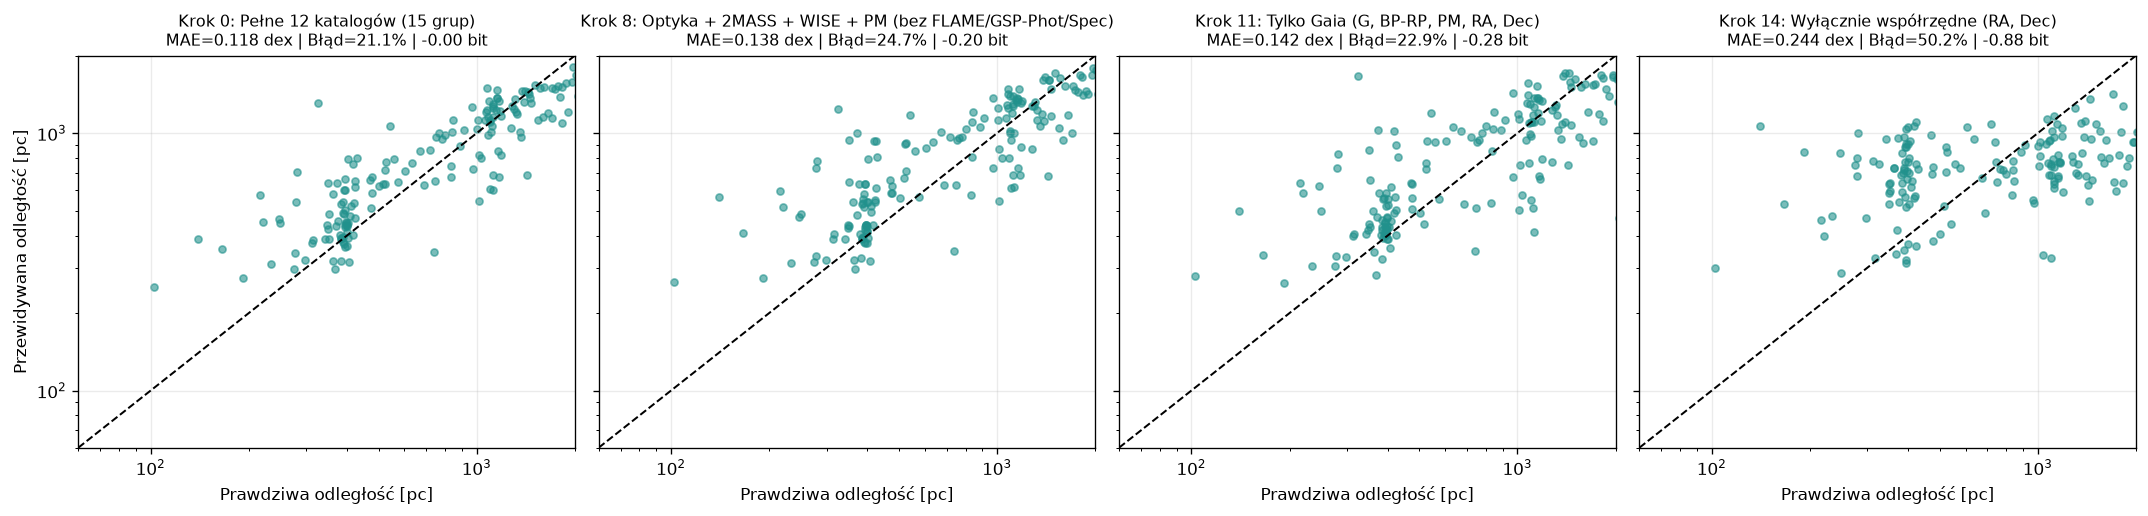

In [5]:
checkpoints = [
    (0, "Krok 0: Pełne 12 katalogów (15 grup)"),
    (8, "Krok 8: Optyka + 2MASS + WISE + PM (bez FLAME/GSP-Phot/Spec)"),
    (11, "Krok 11: Tylko Gaia (G, BP-RP, PM, RA, Dec)"),
    (14, "Krok 14: Wyłącznie współrzędne (RA, Dec)"),
]

fig, axes = plt.subplots(1, 4, figsize=(18, 4.4), sharey=True)
for ax, (st, title_st) in zip(axes, checkpoints):
    pred_d = 10 ** preds_arr[st]
    mae_st = ablation_df.loc[st, "MAE_dex"]
    rel_st = ablation_df.loc[st, "Median_Rel_Error_%"]
    bits_st = ablation_df.loc[st, "Info_Lost_bits"]
    ax.scatter(true_test_d, pred_d, s=18, alpha=0.6, color="#21918c")
    ax.plot([60, 2000], [60, 2000], "k--", lw=1.2)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(60, 2000)
    ax.set_ylim(60, 2000)
    ax.set_xlabel("Prawdziwa odległość [pc]")
    ax.set_title(f"{title_st}\nMAE={mae_st:.3f} dex | Błąd={rel_st:.1f}% | -{bits_st:.2f} bit", fontsize=9.5)

axes[0].set_ylabel("Przewidywana odległość [pc]")
plt.tight_layout()
plt.show()